# 07 · Dynamic programming

Notebook 04 showed that the ideal buy-or-wait rule comes from the Bellman
equation. Here I actually **solve** it: estimate how fares move from day to
day, then work backward from departure in MATLAB to get the best threshold
for every day.

**Key takeaways**
1. Fares follow a **jump process**: on 30–60% of days the fare jumps, and
   jumps pull unusually high or low fares back toward the route's usual
   level (each jump closes about a fifth of the gap).
2. The solved policy has exactly the shape the proof predicts: **buy below a
   threshold that rises as departure approaches**. At the usual fare I'd buy
   immediately from 14 days out, but 60 days out I'd hold out for 30% below
   usual.
3. **From 60 days out, dynamic programming saves about 6% per trip (11–12%
   of total spend)**, roughly double the LightGBM model, because it plans over
   the whole window. **From 30 days out or closer, it loses** on the average
   trip, because its price model is too optimistic that fares will revert.
4. The numerics check out: the grid solution converges at **second order**,
   Monte Carlo simulation agrees within its error (which shrinks like
   $1/\sqrt{N}$), and linear interpolation beats a smoother method because the
   value function has a kink.
5. The lesson: **an optimal policy is only as good as the price model behind
   it.**

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from flight_pricing.backtest import (START_DAYS, buy_day, decision_date, eligible,
                                     load_fare_matrix, price_paid)
from flight_pricing.data import DATA_DIR, connect
from flight_pricing.dp import (DAY_BUCKETS, dp_buy_matrix, fit_jump_model, grid, load_outputs,
                               relative_log_fare, route_reference, run_matlab, save_inputs,
                               transition_matrices)
from flight_pricing.plotting import SERIES, TEXT_MUTED, use_style

use_style()
con = connect()
trips, F = load_fare_matrix(con, full_window_only=False)
flight = pd.to_datetime(trips.flightDate)
TEST_MONTHS = pd.period_range("2022-06", "2022-09", freq="M")
WORK = DATA_DIR / "dp"          # MATLAB input/output files live with the data, outside the repo
WORK.mkdir(exist_ok=True)

## The state: today's fare relative to the route's usual fare

To solve the Bellman equation numerically, I need a **state** that captures
what matters today. I use

$$x_t = \log\frac{P_t}{\text{route's usual fare}}$$

where "usual fare" is the route's median fare over training trips. $x = 0$
means a normal price for that route, and $x = 0.2$ means about 22% above it.
Using a relative state lets one solution work for every route.

I place $x$ on a grid of $K$ points between −1 and 1.5 and describe how it
moves from one day to the next in two ways:

1. **Empirical Markov chain:** count how often fares move from each grid
   point to each other grid point, separately for each number of days left.
   The share of moves from point $i$ that land in point $j$ is the
   maximum-likelihood estimate of the transition probability.
2. **Jump process:** each day the fare stays the same with probability
   $1 - \lambda_t$, or jumps by
   $$J \sim \text{Normal}(\mu_t + \kappa_t\, x_t,\ \sigma_t^2)$$
   A negative $\kappa$ means jumps pull the fare back toward its usual
   level. The parameters are fit by maximum likelihood, separately for each
   range of days.

In [2]:
X_all = relative_log_fare(F, route_reference(F, trips, np.ones(len(trips), bool)))
jump = fit_jump_model(X_all, np.ones(len(trips), bool))
pd.DataFrame({f"{lo}–{hi} days": {k: jump[k][hi] for k in ("lam", "mu", "kappa", "sigma")}
              for lo, hi in DAY_BUCKETS}).T.rename(columns={
    "lam": "P(jump) λ", "mu": "drift μ", "kappa": "pull-back κ", "sigma": "jump size σ"}).round(3)

,P(jump) λ,drift μ,pull-back κ,jump size σ
2–7 days,0.585,0.166,-0.238,0.215
8–14 days,0.526,0.070,-0.238,0.219
15–21 days,0.462,0.020,-0.236,0.222
22–30 days,0.356,0.005,-0.201,0.224
31–45 days,0.315,-0.005,-0.185,0.223
46–60 days,0.292,-0.008,-0.160,0.204


- **The fare jumps on 30–60% of days**, more often near departure.
- **κ is −0.16 to −0.24:** each jump closes about a fifth of the gap to the
  usual fare. A fare 20% above usual tends to fall about 4% at its next jump.
- **The drift μ turns strongly positive in the last week** (+17%): that's
  the late price climb from notebook 02.
- A typical jump is about ±22% (σ), consistent with prices hopping between
  fare classes.

## Solving the Bellman equation in MATLAB

The solver is in [`matlab/backward_induction.m`](../matlab/backward_induction.m).
Its core is three lines:

```matlab
V(:, 2) = cost;                                % day 1: must buy
for c = 3:T
    C(:, c) = M(:, :, c) * V(:, c - 1);        % expected cost of waiting a day
    V(:, c) = min(cost, C(:, c));              % buy now or wait, whichever is cheaper
end
```

Each step is one matrix-vector product, so solving all 60 days on a
60-point grid takes milliseconds. [`matlab/jump_transitions.m`](../matlab/jump_transitions.m)
turns the jump model into a transition matrix on the grid, using `erfc` for
the normal CDF so it runs without extra toolboxes and in GNU Octave.

For the backtest I solve it **separately for each walk-forward month**, with
the route's usual fare, the transition counts and the jump-model parameters
all estimated only from trips that departed before that month.

In [3]:
K = 60
edges, centers = grid(K)
Xs, Ms, params = [], [], {k: [] for k in ("lam", "mu", "kappa", "sigma")}
for m in TEST_MONTHS:
    train = (flight < m.start_time).to_numpy()
    X = relative_log_fare(F, route_reference(F, trips, train))
    Xs.append(X)
    Ms.append(transition_matrices(X, train, K))
    for k, v in fit_jump_model(X, train).items():
        params[k].append(v)
save_inputs(WORK / "dp_input.mat", edges=edges, centers=centers, M_markov=np.stack(Ms, axis=3),
            **{k: np.column_stack(v) for k, v in params.items()})
print(run_matlab("solve_folds", WORK).strip())
solved = load_outputs(WORK / "dp_output.mat")

solved 4 folds x 2 models x 2 objectives on a 60-point grid


## Backtest: does the solved policy save money?

Each day the policy buys if today's cost is no more than the expected cost
of waiting, $\text{cost}(x) \le C_t(x)$, reading $C_t$ off the grid. It's
scored on the same test trips as notebooks 06 and 09.

I also try two objectives:

- **price**: minimize the expected fare paid, which targets dollars and
  total %;
- **log**: minimize the expected log fare, which approximately targets
  average %.

In [4]:
def dp_results(name, objective):
    rows = []
    for s in START_DAYS:
        month = decision_date(trips, s).dt.to_period("M").to_numpy()
        idx = np.flatnonzero(eligible(trips, F, s) & np.isin(month, TEST_MONTHS))
        pct = np.full(len(idx), np.nan)
        for f, m in enumerate(TEST_MONTHS):
            in_m = month[idx] == m
            sel = idx[in_m]
            B = dp_buy_matrix(Xs[f][sel], solved[f"C_{name}_{objective}"][:, :, f], centers, objective)
            pct[in_m] = (F[sel, s] - price_paid(F[sel], buy_day(F[sel], B, s))) / F[sel, s]
        p0 = F[idx, s]
        rows.append({"start": f"{s}d", "price model": name, "objective": objective,
                     "avg_saved_pct": np.nanmean(pct), "total_saved_pct": np.nansum(pct * p0) / p0.sum(),
                     "share_lost_money": np.mean(pct < 0)})
    return rows

dp_table = pd.DataFrame([r for name in ("markov", "jump") for obj in ("price", "log")
                         for r in dp_results(name, obj)])
dp_table.pivot_table(index="start", columns=["price model", "objective"], values="avg_saved_pct",
                     sort=False).round(3)

price model markov          jump       
objective    price    log  price    log
start                                  
60d          0.057  0.048  0.059  0.052
45d          0.016  0.000  0.015  0.006
30d         -0.007 -0.023 -0.011 -0.021
21d         -0.028 -0.048 -0.031 -0.045
14d         -0.040 -0.062 -0.043 -0.057

In [5]:
dp_table[dp_table.objective == "price"].pivot_table(
    index="start", columns="price model", values=["avg_saved_pct", "total_saved_pct", "share_lost_money"],
    sort=False).round(3)

avg_saved_pct        total_saved_pct        share_lost_money  \
price model        markov   jump          markov   jump           markov   
start                                                                      
60d                 0.057  0.059           0.113  0.117            0.077   
45d                 0.016  0.015           0.072  0.072            0.099   
30d                -0.007 -0.011           0.047  0.043            0.115   
21d                -0.028 -0.031           0.014  0.013            0.132   
14d                -0.040 -0.043          -0.024 -0.025            0.143   

                    
price model   jump  
start               
60d          0.080  
45d          0.096  
30d          0.111  
21d          0.134  
14d          0.136

For comparison, LightGBM (notebooks 06 and 09) saved **3.0%, 4.5%, 5.2%, 2.7%
and 0.4%** per trip from 60, 45, 30, 21 and 14 days out.

- **From 60 days out, dynamic programming wins clearly:** about 5.7–5.9% per
  trip and 11–12% of total spend, vs. 3.0% for LightGBM. It plans over the
  whole window and waits through the slow decline that LightGBM's few-week
  view misses.
- **From 30 days out or closer, it loses on the average trip** (while still
  saving a little on total spend). The price model only knows a fare
  relative to the **route's** usual level, so a trip that's consistently
  cheap or expensive (a quiet weekday flight, a holiday weekend) looks like a
  temporary deviation. The policy waits for a pull-back that never comes.
  LightGBM sees more about the trip itself (the cheapest fare so far, recent
  moves) and avoids that.
- **The two price models agree closely**, so the result isn't an accident
  of how the dynamics were estimated.
- **The log objective doesn't help.** I expected it to fix the average-%
  result, but it does slightly worse everywhere. The problem is the price
  model, not the objective.

A natural next step is to combine them: plan with dynamic programming when
starting far out, and switch to LightGBM closer in.

## The shape of the policy

The rest of this notebook uses the jump model fit on all departed trips, on
finer grids, to study the solution itself.

V60(0) by grid: [0.804396 0.805743 0.806103 0.806191 0.806217 0.806223 0.806224]
observed order: [1.9 2.04 1.75 2.14 1.68]
Monte Carlo error: [0.015 0.000507 0.00224 2.1e-05 0.000517]


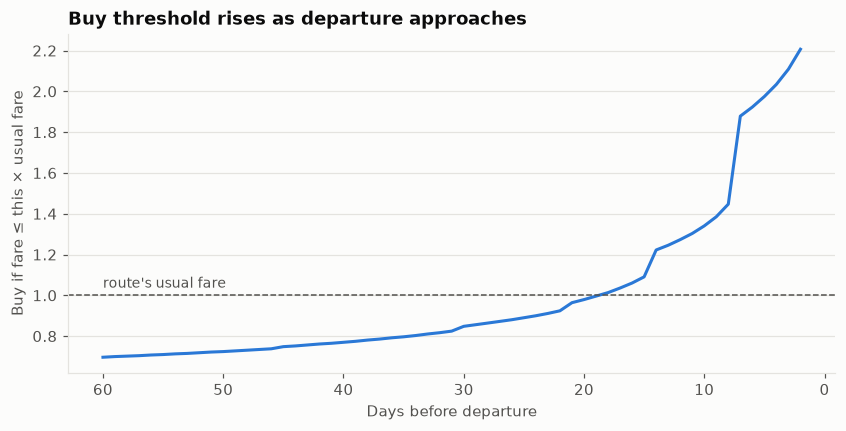

In [6]:
save_inputs(WORK / "study_input.mat", **jump)
print(run_matlab("numerical_study", WORK).strip())
study = load_outputs(WORK / "study_output.mat")

days = np.arange(2, 61)
thresholds = study["thresholds"].ravel()[days]
fig, ax = plt.subplots()
ax.plot(days, np.exp(thresholds), color=SERIES[0])
ax.axhline(1, color=TEXT_MUTED, linewidth=1, linestyle="--")
ax.annotate("route's usual fare", (60, 1), xytext=(0, 5), textcoords="offset points",
            color=TEXT_MUTED, fontsize=9)
ax.set_title("Buy threshold rises as departure approaches")
ax.set_xlabel("Days before departure")
ax.set_ylabel("Buy if fare ≤ this × usual fare")
ax.invert_xaxis()
plt.show()

This is the threshold rule from notebook 04, computed:

- **60 days out:** buy only if the fare is about 30% below the route's usual
  level.
- **About 19 days out:** buy at the usual fare.
- **14 days out and closer:** buy even well above usual, because waiting
  only walks into the late climb.

The sharp steps at 14 and 7 days come from the jump model's day ranges,
which I chose to break at the 21/14/7 deadlines. Between ranges, the
parameters change all at once.

The theorem said the threshold should rise as departure approaches, and the
numerical solution does exactly that.

## The value of waiting (real options)

Having the *right* to wait before buying is like holding an option. At the
route's usual fare ($x = 0$), its value is the expected saving from
optimal waiting:

$$\text{value of waiting}_t = 1 - V_t(0)$$

in units of the usual fare.

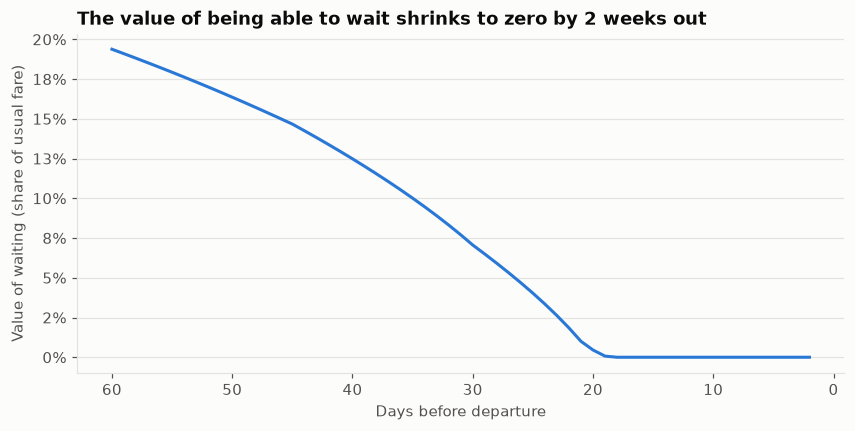

In [7]:
option_value = study["option_value"].ravel()[days]
fig, ax = plt.subplots()
ax.plot(days, option_value, color=SERIES[0])
ax.set_title("The value of being able to wait shrinks to zero by 2 weeks out")
ax.set_xlabel("Days before departure")
ax.set_ylabel("Value of waiting (share of usual fare)")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.invert_xaxis()
plt.show()

According to the price model, the right to wait is worth about **19% of the
fare 60 days out**, 8% at 30 days, and nothing by 14 days. That's why the
policy buys immediately at the usual fare from two weeks out.

The backtest saved much less than 19%. The gap is the price model's
optimism about pull-back, the same issue as above. Like an option priced with
the wrong volatility, the value is only as good as the model of the
underlying.

## Numerical checks

### 1. Does the grid solution converge?

I solve on grids from 25 to 1,600 points and track $V_{60}(0)$, the expected
price paid starting 60 days out at the usual fare.

In [8]:
conv = pd.DataFrame({"grid points K": study["Ks"].ravel(), "V60(0)": study["v60"].ravel(),
                     "day-30 threshold": study["b30"].ravel(), "seconds": study["runtime"].ravel()})
conv["change from previous K"] = conv["V60(0)"].diff().abs()
conv["observed order"] = np.r_[np.nan, np.nan, study["order"].ravel()]
display_conv = conv.copy()
display_conv

,grid points K,V60(0),day-30 threshold,seconds,change from previous K,observed order
0,25,0.804396,-0.250000,0.069277,NaN,NaN
1,50,0.805743,-0.175000,0.021852,0.001346,NaN
2,100,0.806103,-0.187500,0.047338,0.000360,1.902193
3,200,0.806191,-0.168750,0.138811,0.000088,2.039444
4,400,0.806217,-0.165625,0.387042,0.000026,1.745935
5,800,0.806223,-0.164062,1.087573,0.000006,2.144661
6,1600,0.806224,-0.164844,3.064166,0.000002,1.679882


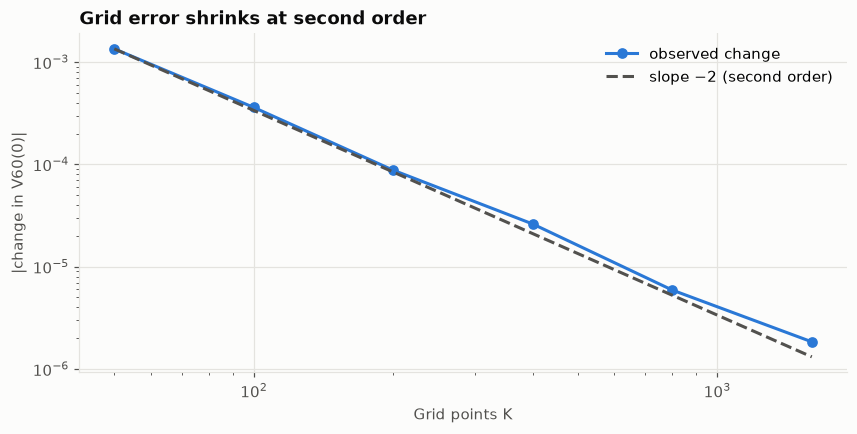

In [9]:
fig, ax = plt.subplots()
d = conv.dropna(subset=["change from previous K"])
d = d[d["change from previous K"] > 0]
ax.loglog(d["grid points K"], d["change from previous K"], "o-", color=SERIES[0], label="observed change")
ref = d["change from previous K"].iloc[0] * (d["grid points K"].iloc[0] / d["grid points K"]) ** 2
ax.loglog(d["grid points K"], ref, "--", color=TEXT_MUTED, label="slope −2 (second order)")
ax.set_title("Grid error shrinks at second order")
ax.set_xlabel("Grid points K")
ax.set_ylabel("|change in V60(0)|")
ax.grid(axis="x")
ax.legend()
plt.show()

Each doubling of $K$ cuts the change by about 4×, an observed order close to
**2**. That's what a midpoint grid should give: the discretization error
scales like $h^2$, where $h$ is the grid spacing. From 400 points on, the
answer is stable to five decimals. The runtime grows roughly with $K^2$
(each step is a $K \times K$ matrix-vector product), and it's still under 3
seconds at 1,600 points.

### 2. Does simulation agree? (Monte Carlo)

I simulate the jump process directly, following the policy along each
simulated path, and average the price paid over $N$ paths.

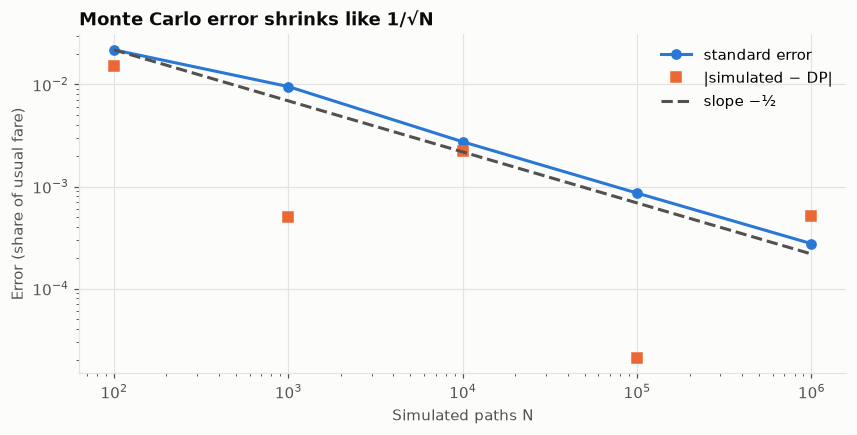

,paths N,simulated mean,standard error,|error| vs. DP,error / std. error
0,100,0.791216,0.021834,0.015009,0.687391
1,1000,0.806731,0.009536,0.000507,0.053174
2,10000,0.808468,0.002744,0.002243,0.817478
3,100000,0.806203,0.000862,0.000021,0.024318
4,1000000,0.806741,0.000276,0.000517,1.875369


In [10]:
mc = pd.DataFrame({"paths N": study["Ns"].ravel(), "simulated mean": study["mc_mean"].ravel(),
                   "standard error": study["mc_se"].ravel(), "|error| vs. DP": study["mc_error"].ravel()})
mc["error / std. error"] = mc["|error| vs. DP"] / mc["standard error"]

fig, ax = plt.subplots()
ax.loglog(mc["paths N"], mc["standard error"], "o-", color=SERIES[0], label="standard error")
ax.loglog(mc["paths N"], mc["|error| vs. DP"], "s", color=SERIES[1], label="|simulated − DP|")
ref = mc["standard error"].iloc[0] * np.sqrt(mc["paths N"].iloc[0] / mc["paths N"])
ax.loglog(mc["paths N"], ref, "--", color=TEXT_MUTED, label="slope −½")
ax.set_title("Monte Carlo error shrinks like 1/√N")
ax.set_xlabel("Simulated paths N")
ax.set_ylabel("Error (share of usual fare)")
ax.grid(axis="x")
ax.legend()
plt.show()
mc

The standard error follows the $1/\sqrt{N}$ line exactly (central limit
theorem), and the gap between simulation and the DP solution stays within
about 2 standard errors at every $N$. With a million paths the two agree to
about 0.05% of the fare. The small remaining gap is expected: the simulation
moves the fare continuously, while the DP rounds it to grid points.

### 3. Which interpolation between grid points?

The policy needs $C_t(x)$ between grid points. I compare linear and
shape-preserving cubic (pchip) interpolation on a coarse 50-point grid,
against the 1,600-point solution, by how often they give the wrong buy/wait
decision.

In [11]:
pd.Series(study["interp_err"].mean(axis=1), index=["linear", "pchip"],
          name="share of wrong decisions").to_frame().round(4)

,share of wrong decisions
linear,0.0025
pchip,0.0183


**Linear wins**: 0.25% wrong decisions vs. 1.8% for pchip. That surprised me
at first, since higher-order interpolation is usually more accurate. But the
value function $V_t(x) = \min\{\text{cost}(x), C_t(x)\}$ has a **kink** where
buying and waiting are equally good, and a smooth cubic assumes there isn't
one. Linear interpolation makes no smoothness assumption, so it handles the
kink better.

## Next

- **Notebook 08** learns the policy directly from price paths with
  reinforcement learning, without assuming a price model at all. That's a
  direct test of whether the model assumptions are what hold DP back.
- **Notebook 09** will add the DP policy to the final comparison.